# 03 — Análise bivariada, regressão múltipla e regressão logística

**Global Solution 2026.2 · MLAM · Citizen Tech** · **Integrantes:** Davi Queiroz Zuolo (RM 571669) · Gustavo Zagato Bottechia (RM 569420) · Daniel Vilela Mana (RM 571632)

Base: `dados/od2017_sp_trabalho.csv` (gerada em `01_preparacao.ipynb`), uma linha por trabalhador.

| Item | Pergunta | Modelo |
|---|---|---|
| 04 | A distância explica a duração da viagem de ônibus? | regressão linear simples |
| 05 | Renda, carros e idade acrescentam algo? | regressão linear múltipla |
| 06 | Quem usa ônibus para trabalhar? | regressão logística binária |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn import metrics
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import Markdown, display

pd.set_option("display.float_format", "{:,.4f}".format)
df = pd.read_csv("dados/od2017_sp_trabalho.csv")
onibus = df[df.usa_onibus == 1]

def sem_outliers(d, colunas):
    """Mantém as linhas dentro de [Q1 - 1,5·IQR, Q3 + 1,5·IQR] em todas as colunas."""
    q1, q3 = d[colunas].quantile(0.25), d[colunas].quantile(0.75)
    folga = 1.5 * (q3 - q1)
    return d[d[colunas].ge(q1 - folga).all(axis=1) & d[colunas].le(q3 + folga).all(axis=1)]

limpo = sem_outliers(onibus, ["duracao", "distancia_km"])
print(f"viagens de ônibus ao trabalho: {len(onibus):,} | removidas como outliers (IQR): {len(onibus) - len(limpo):,} "
      f"({1 - len(limpo) / len(onibus):.1%}) | usadas nos itens 04 e 05: {len(limpo):,}")

viagens de ônibus ao trabalho: 4,289 | removidas como outliers (IQR): 178 (4.2%) | usadas nos itens 04 e 05: 4,111


## Item 04 — Análise bivariada: duração × distância
Variáveis quantitativas: **`distancia_km`** (explicativa) e **`duracao`** em minutos (resposta), para as viagens de ônibus ao trabalho.

### a) Gráfico de dispersão, d) com a reta de regressão

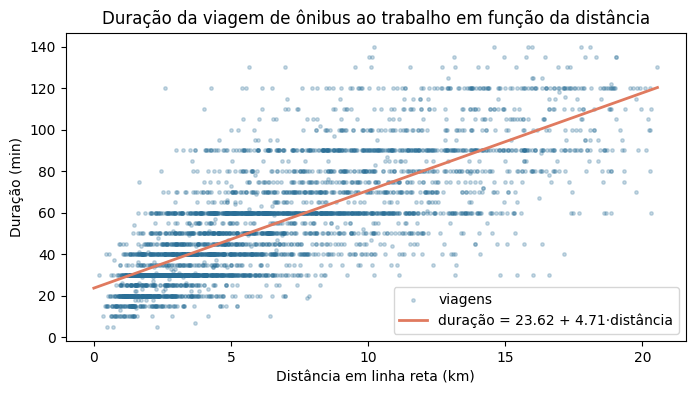

In [2]:
simples = smf.ols("duracao ~ distancia_km", limpo).fit()
b0, b1 = simples.params
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(limpo.distancia_km, limpo.duracao, s=6, alpha=0.25, color="#2a6f97", label="viagens")
xs = np.array([0, limpo.distancia_km.max()])
ax.plot(xs, b0 + b1 * xs, color="#e07a5f", lw=2, label=f"duração = {b0:.2f} + {b1:.2f}·distância")
ax.set(title="Duração da viagem de ônibus ao trabalho em função da distância", xlabel="Distância em linha reta (km)", ylabel="Duração (min)")
ax.legend(); plt.show()

**Interpretação (a).** A nuvem sobe da esquerda para a direita: viagens mais longas em distância demoram mais. A relação é aproximadamente linear, com dispersão que aumenta com a distância. As faixas horizontais aparecem porque as pessoas declaram a duração em múltiplos de 5 minutos.

### b) Covariância e correlação de Pearson, c) gráfico de correlação

covariância = **94.91** min·km · correlação de Pearson r = **0.769**

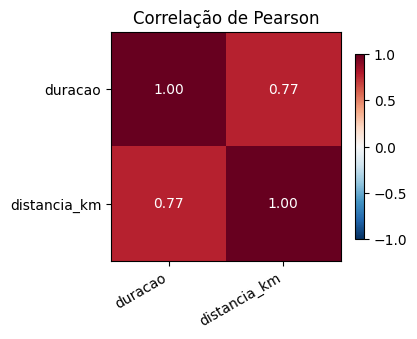

In [3]:
cov = limpo.duracao.cov(limpo.distancia_km)
r = limpo.duracao.corr(limpo.distancia_km)
display(Markdown(f"covariância = **{cov:.2f}** min·km · correlação de Pearson r = **{r:.3f}**"))

def mapa_correlacao(d, titulo):
    c = d.corr()
    fig, ax = plt.subplots(figsize=(1.1 * len(c) + 1.5, 1.0 * len(c) + 1))
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=30, ha="right"); ax.set_yticks(range(len(c)), c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", color="white" if abs(c.iloc[i, j]) > 0.5 else "black")
    ax.set_title(titulo); fig.colorbar(im, shrink=0.8); plt.show()

mapa_correlacao(limpo[["duracao", "distancia_km"]], "Correlação de Pearson")

**Interpretação (b, c).** A covariância positiva indica que as duas variáveis crescem juntas, mas seu valor depende das unidades (min·km) e não mede a força da relação. A correlação de Pearson padroniza a covariância para o intervalo $[-1, 1]$: valores acima de 0,7 indicam associação linear positiva forte.

### d) Equação, e) adequação do modelo, f) previsão

In [4]:
display(Markdown(
    f"**Equação:** duração = {b0:.2f} + {b1:.2f} · distância_km\n\n"
    f"**R² = {simples.rsquared:.4f}** · **F = {simples.fvalue:,.1f}** (p-valor {simples.f_pvalue:.2e}) · n = {int(simples.nobs):,}\n\n"
    f"**Previsão:** uma viagem de ônibus de 10 km deve durar {simples.predict(pd.DataFrame({'distancia_km': [10]}))[0]:.0f} min."))
display(simples.summary().tables[1])

**Equação:** duração = 23.62 + 4.71 · distância_km

**R² = 0.5920** · **F = 5,962.6** (p-valor 0.00e+00) · n = 4,111

**Previsão:** uma viagem de ônibus de 10 km deve durar 71 min.

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,23.6165,0.487,48.447,0.000,22.661,24.572
distancia_km,4.7060,0.061,77.218,0.000,4.587,4.826


**Interpretação (d, e, f)**
- **Intercepto:** é o tempo que a viagem leva mesmo a uma distância próxima de zero: caminhada até o ponto, espera e embarque.
- **Inclinação:** minutos a mais por quilômetro. O inverso (60 ÷ inclinação) é a velocidade média porta a porta em linha reta.
- **R²:** fração da variação da duração explicada pela distância. O restante se deve a fatores não observados (trânsito, baldeações, espera).
- **Teste F:** testa $H_0$: a inclinação é zero. Com p-valor praticamente nulo, rejeita-se $H_0$: o modelo é significativo.
- **Limitação:** a distância é em linha reta, não o trajeto real da linha.

## Item 05 — Regressão linear múltipla
Resposta: `duracao`. Explicativas quantitativas: **`distancia_km`, `renda_pc`, `qt_auto`, `idade`** (quatro variáveis; o enunciado pede pelo menos três).

### a) Gráficos de dispersão

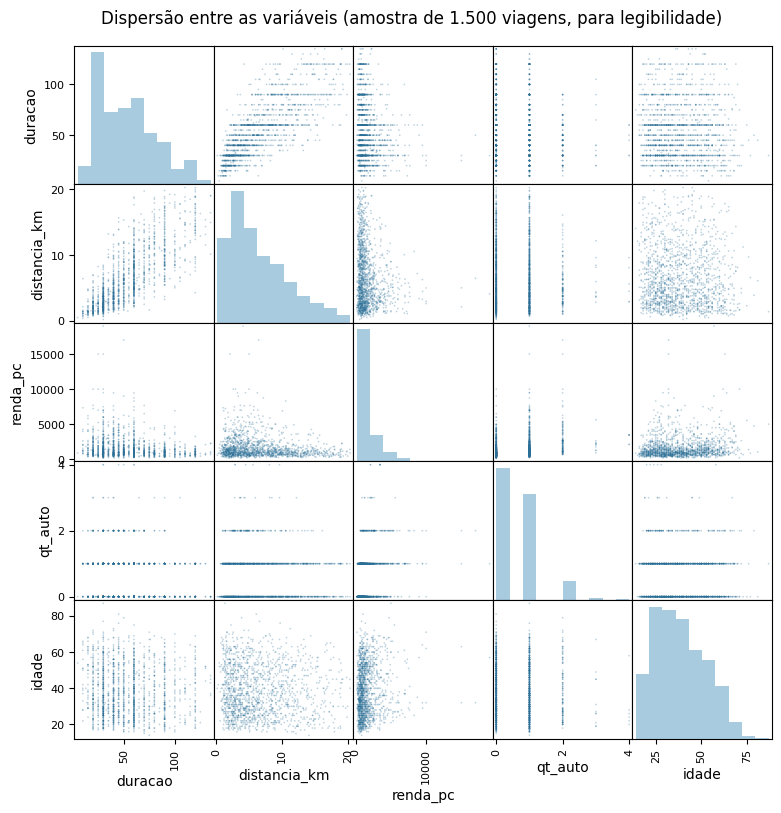

In [5]:
VARS = ["duracao", "distancia_km", "renda_pc", "qt_auto", "idade"]
pd.plotting.scatter_matrix(limpo[VARS].sample(1500, random_state=0), figsize=(9, 9), s=6, alpha=0.3, color="#2a6f97", hist_kwds={"color": "#a9cbe0"})
plt.suptitle("Dispersão entre as variáveis (amostra de 1.500 viagens, para legibilidade)", y=0.92); plt.show()

**Interpretação (a).** Na primeira linha (duração contra cada variável) só a distância mostra tendência clara. Renda, carros e idade formam nuvens sem inclinação visível.

### b) Matrizes de covariância e de correlação, c) gráfico de correlação

,duracao,distancia_km,renda_pc,qt_auto,idade
duracao,754.4200,94.9100,"-7,540.1200",-1.0500,-14.1000
distancia_km,94.9100,20.1700,"-1,153.5500",-0.0900,-2.8400
renda_pc,"-7,540.1200","-1,153.5500","2,591,980.0400",290.5500,"2,471.8000"
qt_auto,-1.0500,-0.0900,290.5500,0.4400,-0.0000
idade,-14.1000,-2.8400,"2,471.8000",-0.0000,189.5000


,duracao,distancia_km,renda_pc,qt_auto,idade
duracao,1.0000,0.7690,-0.1710,-0.0570,-0.0370
distancia_km,0.7690,1.0000,-0.1600,-0.0310,-0.0460
renda_pc,-0.1710,-0.1600,1.0000,0.2720,0.1120
qt_auto,-0.0570,-0.0310,0.2720,1.0000,-0.0000
idade,-0.0370,-0.0460,0.1120,-0.0000,1.0000


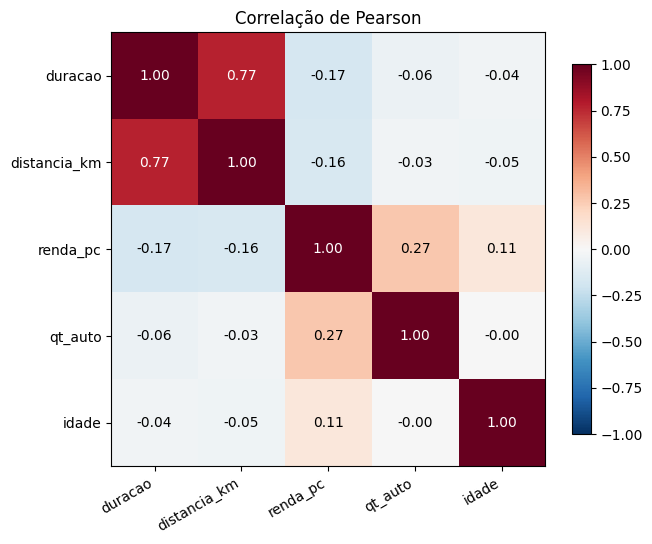

In [6]:
display(limpo[VARS].cov().round(2)); display(limpo[VARS].corr().round(3))
mapa_correlacao(limpo[VARS], "Correlação de Pearson")

**Interpretação (b, c).** A duração tem correlação forte só com a distância. Renda per capita e número de carros são correlacionados entre si de forma moderada (famílias mais ricas têm mais carros), sem atingir um nível que comprometa a regressão. As covariâncias que envolvem `renda_pc` são grandes só porque a renda está em reais: a unidade infla o número.

### d) Equação, e) adequação, f) previsão

In [7]:
multipla = smf.ols("duracao ~ distancia_km + renda_pc + qt_auto + idade", limpo).fit()
p = multipla.params
display(Markdown(
    f"**Equação:** duração = {p.Intercept:.2f} {p.distancia_km:+.3f}·distância_km {p.renda_pc:+.5f}·renda_pc {p.qt_auto:+.3f}·qt_auto {p.idade:+.4f}·idade\n\n"
    f"**R² = {multipla.rsquared:.4f}** · R² ajustado = {multipla.rsquared_adj:.4f} · **F = {multipla.fvalue:,.1f}** (p-valor {multipla.f_pvalue:.2e})\n\n"
    f"R² da regressão simples: {simples.rsquared:.4f} → ganho de {multipla.rsquared - simples.rsquared:.4f}"))
display(multipla.summary().tables[1])

novo = pd.DataFrame({"distancia_km": [10], "renda_pc": [1500], "qt_auto": [0], "idade": [35]})
print(f"Previsão: 10 km, renda per capita de R$ 1.500, sem carro, 35 anos -> {multipla.predict(novo)[0]:.0f} min")

com = smf.ols("duracao ~ distancia_km + renda_pc + qt_auto + idade", onibus).fit()
print(f"Efeito do corte de outliers: R² com outliers = {com.rsquared:.4f} (n = {int(com.nobs):,}) | sem outliers = {multipla.rsquared:.4f} (n = {int(multipla.nobs):,})")

**Equação:** duração = 25.46 +4.660·distância_km -0.00074·renda_pc -0.894·qt_auto +0.0051·idade

**R² = 0.5948** · R² ajustado = 0.5944 · **F = 1,506.9** (p-valor 0.00e+00)

R² da regressão simples: 0.5920 → ganho de 0.0028

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,25.4615,0.981,25.949,0.000,23.538,27.385
distancia_km,4.6603,0.062,75.683,0.000,4.540,4.781
renda_pc,-0.0007,0.000,-4.123,0.000,-0.001,-0.000
qt_auto,-0.8942,0.427,-2.095,0.036,-1.731,-0.057
idade,0.0051,0.020,0.257,0.797,-0.034,0.044


Previsão: 10 km, renda per capita de R$ 1.500, sem carro, 35 anos -> 71 min
Efeito do corte de outliers: R² com outliers = 0.5994 (n = 4,289) | sem outliers = 0.5948 (n = 4,111)


**Interpretação (d, e, f)**
- Cada coeficiente é o efeito de uma unidade a mais daquela variável **mantidas as outras fixas**.
- O teste F rejeita $H_0$ (todos os coeficientes iguais a zero): o modelo é significativo como um todo.
- O R² quase não muda em relação à regressão simples. **Conclusão:** depois de considerar a distância, renda, carros e idade praticamente não explicam a duração da viagem de ônibus. O tempo no ônibus depende de **onde** a pessoa mora e trabalha, não de quem ela é.
- Variáveis com p-valor acima de 0,05 na tabela não têm efeito estatisticamente distinguível de zero.
- O R² com e sem outliers é praticamente o mesmo: os valores extremos não estavam conduzindo o resultado.

## Item 06 — Regressão logística binária
Resposta: **`usa_onibus`** (1 = o modo principal da viagem ao trabalho é ônibus). Explicativas quantitativas: **`log_renda_pc`, `qt_auto`, `distancia_km`, `idade`**.

**Por que `duracao` não entra:** ela é consequência do modo (ônibus demora mais). Usá-la seria prever a resposta olhando para o efeito dela.

**Divisão dos dados:** 80% treino e 20% teste, estratificada pela resposta e **agrupada por família**: moradores da mesma casa têm a mesma renda e o mesmo carro, então ficam todos do mesmo lado. O modelo é ajustado no treino e avaliado no teste, que ele nunca viu.

In [8]:
def dobras(d, k=5, semente=42):
    return StratifiedGroupKFold(k, shuffle=True, random_state=semente).split(d, d.usa_onibus, d.id_fam)

i_treino, i_teste = next(dobras(df))
treino, teste = df.iloc[i_treino], df.iloc[i_teste]
assert not set(treino.id_fam) & set(teste.id_fam)
print(f"treino: {len(treino):,} ({treino.usa_onibus.mean():.1%} usam ônibus) | teste: {len(teste):,} ({teste.usa_onibus.mean():.1%} usam ônibus)")

FORMULA = "usa_onibus ~ log_renda_pc + qt_auto + distancia_km + idade"
logit = smf.logit(FORMULA, treino).fit(disp=0)

treino: 15,522 (22.3% usam ônibus) | teste: 3,940 (21.1% usam ônibus)


### a) Equação
$$P(\text{usa ônibus}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_4 x_4)}}$$

In [9]:
b = logit.params
display(Markdown(f"**logit(P) = {b.Intercept:.4f} {b.log_renda_pc:+.4f}·log_renda_pc {b.qt_auto:+.4f}·qt_auto {b.distancia_km:+.4f}·distancia_km {b.idade:+.4f}·idade**"))
display(pd.DataFrame({"coeficiente": b, "razão de chances": np.exp(b), "p-valor": logit.pvalues}))

**logit(P) = 2.5304 -0.4280·log_renda_pc -0.6436·qt_auto +0.0164·distancia_km -0.0062·idade**

,coeficiente,razão de chances,p-valor
Intercept,2.5304,12.5585,0.0000
log_renda_pc,-0.4280,0.6518,0.0000
qt_auto,-0.6436,0.5254,0.0000
distancia_km,0.0164,1.0166,0.0000
idade,-0.0062,0.9938,0.0001


**Interpretação (a).** A razão de chances ($e^{\beta}$) é o fator pelo qual a chance de usar ônibus é multiplicada quando a variável sobe uma unidade, com as demais fixas. Abaixo de 1, a chance diminui; acima de 1, aumenta. Todos os p-valores abaixo de 0,05 indicam efeitos distinguíveis de zero.

### b) Matriz de confusão e acurácia
Só cerca de um quinto dos trabalhadores usa ônibus. Com o limiar padrão de 0,5 o modelo quase nunca prevê "usa". Por isso o limiar é escolhido para maximizar o F1, usando **validação cruzada dentro do treino** (5 dobras): cada trabalhador do treino recebe uma probabilidade de um modelo que não o viu. O teste não participa da escolha.

In [10]:
p_cv = pd.Series(np.nan, index=treino.index)
for a, v in dobras(treino):
    p_cv.iloc[v] = smf.logit(FORMULA, treino.iloc[a]).fit(disp=0).predict(treino.iloc[v])
grade = np.arange(0.05, 0.96, 0.01)
limiar = float(grade[np.argmax([metrics.f1_score(treino.usa_onibus, p_cv >= t) for t in grade])])

p_teste = logit.predict(teste)
def avaliar(lim):
    prev = p_teste >= lim
    return {"acurácia": metrics.accuracy_score(teste.usa_onibus, prev), "precisão": metrics.precision_score(teste.usa_onibus, prev, zero_division=0),
            "recall": metrics.recall_score(teste.usa_onibus, prev), "F1": metrics.f1_score(teste.usa_onibus, prev)}
tabela = pd.DataFrame({"limiar 0,50 (padrão)": avaliar(0.5), f"limiar {limiar:.2f} (escolhido no treino)": avaliar(limiar)})
display(tabela)
matriz = pd.DataFrame(metrics.confusion_matrix(teste.usa_onibus, p_teste >= limiar),
                      index=["real: não usa", "real: usa"], columns=["previsto: não usa", "previsto: usa"])
display(matriz)
maioria = max(teste.usa_onibus.mean(), 1 - teste.usa_onibus.mean())
print(f"AUC = {metrics.roc_auc_score(teste.usa_onibus, p_teste):.3f} | acurácia de prever sempre 'não usa': {maioria:.3f}")

,"limiar 0,50 (padrão)",limiar 0.21 (escolhido no treino)
acurácia,0.7822,0.6320
precisão,0.2941,0.3300
recall,0.0241,0.7253
F1,0.0445,0.4537


,previsto: não usa,previsto: usa
real: não usa,1888,1222
real: usa,228,602


AUC = 0.705 | acurácia de prever sempre 'não usa': 0.789


**Interpretação (b)**
- **Matriz de confusão:** a diagonal principal são os acertos. Na linha "real: usa", a coluna da direita são os usuários de ônibus que o modelo encontrou; a da esquerda, os que ele perdeu.
- **Acurácia:** proporção de acertos. Ela precisa ser comparada com a acurácia de prever sempre a classe mais comum. No limiar 0,5 as duas são parecidas, mas o modelo praticamente não identifica quem usa ônibus (recall próximo de zero): a acurácia sozinha engana quando as classes são desbalanceadas.
- **Limiar escolhido:** a acurácia cai, e o recall sobe muito. Para planejar oferta, deixar de identificar quem depende do ônibus custa mais do que um alarme falso, então essa troca é a adequada.
- **AUC:** mede a capacidade de ordenar quem usa acima de quem não usa, sem depender do limiar (0,5 = sorteio; 1 = perfeito). O valor obtido indica um poder de discriminação moderado: quatro variáveis socioeconômicas não bastam para explicar a escolha do modo.

### c) Classificação

In [11]:
perfis = pd.DataFrame({"renda_pc": [1000, 1000, 5000], "qt_auto": [0, 1, 2], "distancia_km": [8, 8, 8], "idade": [30, 30, 45]},
                      index=["A: renda baixa, sem carro", "B: renda baixa, 1 carro", "C: renda alta, 2 carros"])
perfis["P(usa ônibus)"] = logit.predict(perfis.assign(log_renda_pc=np.log(perfis.renda_pc)))
perfis["classificação"] = np.where(perfis["P(usa ônibus)"] >= limiar, "usa ônibus", "não usa")
display(perfis)

,renda_pc,qt_auto,distancia_km,idade,P(usa ônibus),classificação
"A: renda baixa, sem carro",1000,0,8,30,0.3823,usa ônibus
"B: renda baixa, 1 carro",1000,1,8,30,0.2454,usa ônibus
"C: renda alta, 2 carros",5000,2,8,45,0.0725,não usa


**Interpretação (c).** Três trabalhadores que moram à mesma distância do trabalho recebem classificações diferentes conforme a renda e, principalmente, o número de carros em casa. A probabilidade cai de forma acentuada a cada carro.

### Complemento: o que melhora o modelo
O modelo acima atende ao enunciado com quatro variáveis quantitativas. Acrescentando o vínculo de trabalho (CLT), o grupo de ocupação e uma forma não linear para a distância, a capacidade de discriminação aumenta.

In [12]:
AMPLA = FORMULA + " + np.log(distancia_km) + clt + pico + C(ocupacao)"
ampliado = smf.logit(AMPLA, treino).fit(disp=0)
p_amp = ampliado.predict(teste)
display(pd.DataFrame({"AUC no teste": [metrics.roc_auc_score(teste.usa_onibus, p_teste), metrics.roc_auc_score(teste.usa_onibus, p_amp)],
                      "pseudo-R² (McFadden)": [logit.prsquared, ampliado.prsquared]}, index=["4 quantitativas", "ampliado"]))
so_declarada = smf.logit(FORMULA, treino[treino.renda_declarada == 1]).fit(disp=0)
print(f"Robustez: coeficiente de log_renda_pc com todas as famílias = {b.log_renda_pc:.3f}; só com renda declarada = {so_declarada.params.log_renda_pc:.3f}")

,AUC no teste,pseudo-R² (McFadden)
4 quantitativas,0.7050,0.0812
ampliado,0.8138,0.2102


Robustez: coeficiente de log_renda_pc com todas as famílias = -0.428; só com renda declarada = -0.361


## Limitações
1. **Dados de 2017**, anteriores à pandemia e à expansão do trabalho remoto e dos aplicativos de transporte.
2. **Renda atribuída** pela pesquisa em boa parte das famílias; o teste de robustez acima compara o coeficiente com e sem essas famílias.
3. **Distância em linha reta**, não o trajeto real.
4. **Duração declarada** pelo entrevistado, arredondada em múltiplos de 5 minutos.
5. **Associação, não causa:** os modelos descrevem quem usa ônibus; não provam que mudar a renda ou a posse de carro de uma pessoa mudaria seu comportamento na mesma medida.
6. **Regressões ajustadas na amostra**, sem os fatores de expansão da pesquisa: os coeficientes descrevem os entrevistados, e a generalização para a população é aproximada.